# Exercise 2: my Lesson 0.3 GPU benchmarks

Data: `benchmarks.csv`, the 5000×5000 matrix-multiply times from Lesson 0.3, on my M5 Pro Mac and on Colab.

Goal: load it, show it as a table, plot it, then **Restart and run all** to prove it works top to bottom.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## Load the CSV
The last line of the cell is `df`, so it shows as a formatted table. `print(df)` would give plain text.

In [2]:
df = pd.read_csv("benchmarks.csv")
df

,machine,device,run,seconds
0,M5 Pro Mac,CPU,1,0.177
1,M5 Pro Mac,CPU,2,0.153
2,M5 Pro Mac,MPS GPU,1,0.216
3,M5 Pro Mac,MPS GPU,2,0.055
4,Colab,CPU,1,2.147
5,Colab,CPU,2,2.034
6,Colab,T4 GPU,1,0.190
7,Colab,T4 GPU,2,0.088


## Keep only run 2
Run 1 includes the GPU's start-up cost, so run 2 is the fair comparison.

In [3]:
run2 = df[df["run"] == 2]
run2

,machine,device,run,seconds
1,M5 Pro Mac,CPU,2,0.153
3,M5 Pro Mac,MPS GPU,2,0.055
5,Colab,CPU,2,2.034
7,Colab,T4 GPU,2,0.088


## Plot it

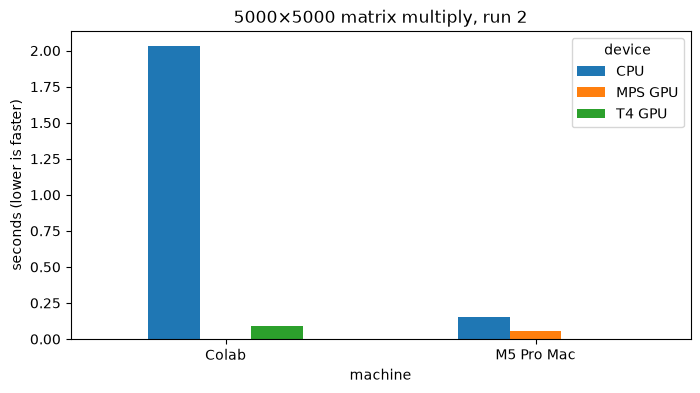

In [4]:
ax = run2.pivot(index="machine", columns="device", values="seconds").plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("seconds (lower is faster)")
ax.set_title("5000×5000 matrix multiply, run 2")
plt.show()

## What the chart shows
Colab's CPU bar towers over everything, which is why Colab's speedup looked so big. Compare the two GPU bars directly.